In [2]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "Eu ainda acho que isso era uma péssima ideia",
    "Mas a gente precisava ver o que tinha lá",
    "Você quase me matou de susto",
    "Eu quase morri foi vendo aquilo",
    "Não fala tão alto",
    "Tem alguém vindo",
    "Fica quieto",
    "Acho que passou",
    "Tomara",
    "A gente precisa voltar antes que percebam",
    "Já era tarde para isso",
    "Eles vão descobrir",
    "Se descobrirem, estamos perdidos",
    "Então anda logo",
    "Por aqui",
    "Esse corredor parece mais comprido de noite",
    "Tudo parece pior de noite",
    "Principalmente quando está vazio",
    "E silencioso",
    "Silêncio demais nunca é bom sinal",
    "Olha ali",
    "O retrato se mexeu",
    "Ele está olhando para a gente",
    "Não para",
    "Não estamos fazendo nada de errado",
    "Só estamos totalmente fora do lugar",
    "Essa não é uma boa defesa",
    "Eu sei",
    "Mas foi o que eu consegui pensar",
    "Espere",
    "A porta da cozinha está aberta",
    "Agora sim estamos salvos",
    "Salvos de quê?",
    "De morrer de fome",
    "Você só pensa em comida",
    "Depois dessa noite, sim",
    "Entra logo",
    "Que cheiro bom é esse?",
    "Parece pão fresco",
    "E torta de abóbora",
    "Agora você falou a minha língua",
    "Olha quantos pratos",
    "Tem comida suficiente para um batalhão",
    "Ou para dois alunos famintos",
    "Só pega o suficiente",
    "Eu vou pegar um pouco mais",
    "Você é impossível",
    "Impossível e com fome",
    "Depois a gente inventa uma desculpa",
    "Primeiro eu vou comer",
    "Depois eu penso no resto"
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2838.93it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(51, 768)
[[-7.9419492e-03  3.7282947e-02 -2.5404070e-02 ... -4.4226687e-02
  -2.6724856e-02 -1.6109757e-03]
 [ 9.9120345e-03  1.9105081e-02 -1.8876646e-02 ... -5.2682806e-02
  -3.0341038e-02  1.7144725e-02]
 [ 2.8282557e-02  3.9291456e-02 -2.9923076e-02 ... -5.2331127e-02
  -5.5672973e-02  2.7104363e-02]
 ...
 [ 5.8523817e-03  1.4701494e-03 -2.0511735e-02 ... -6.5485008e-02
  -4.8517957e-02 -3.1050437e-03]
 [ 4.7417838e-05  4.8947811e-02 -3.2012768e-02 ... -5.8930658e-02
  -3.1603426e-02  2.1904007e-02]
 [-2.4046965e-03  2.8355738e-02 -3.2345518e-02 ... -5.1824506e-02
  -4.0294416e-02  1.2926945e-02]]


In [3]:
S = model.encode(sentences_e5, normalize_embeddings=False)

scores = np.dot(S, S.T)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i:
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.88277781 0.         0.         ... 0.         0.         0.        ]
 [0.87422419 0.85332882 0.         ... 0.         0.         0.        ]
 ...
 [0.85796046 0.87220418 0.85612905 ... 0.         0.         0.        ]
 [0.8341459  0.83967155 0.85763866 ... 0.85321808 0.         0.        ]
 [0.85717678 0.85571194 0.84528702 ... 0.88756514 0.87841296 0.        ]]


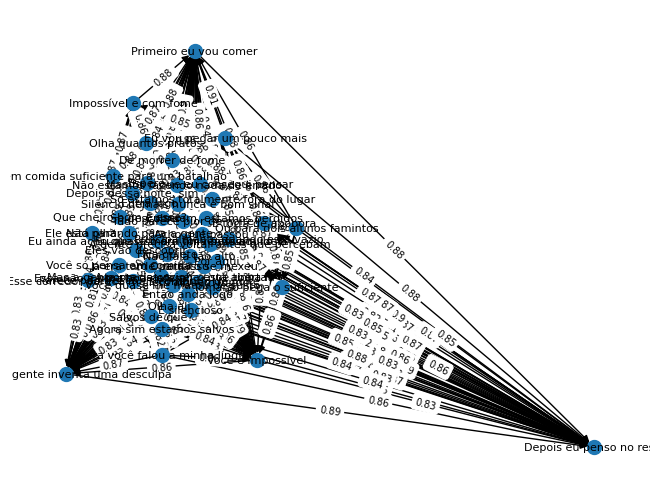

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

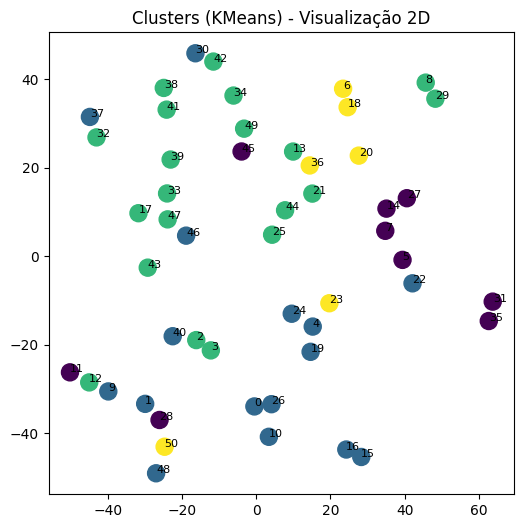

In [16]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

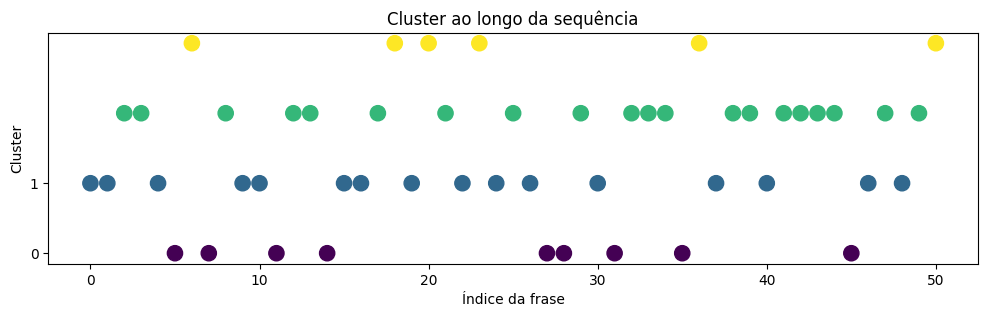

In [17]:
plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,1])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

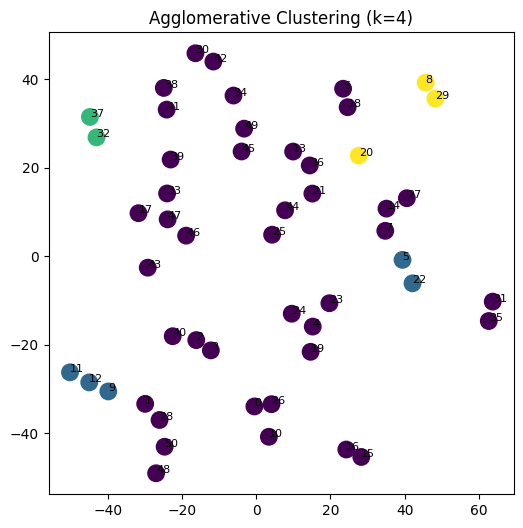

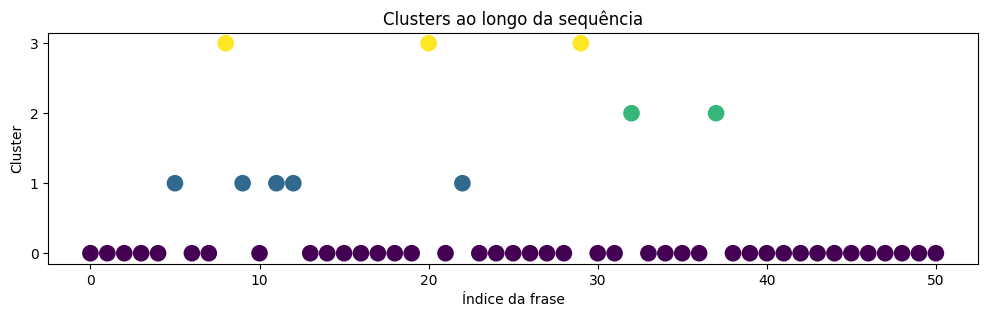

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE

S_norm = normalize(S)


k = 4
clustering = AgglomerativeClustering(
    n_clusters=k,
    metric='cosine',
    linkage='average'
)

labels = clustering.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)

plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=140)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title(f"Agglomerative Clustering (k={k})")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks(range(k))
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Clusters ao longo da sequência")

plt.show()

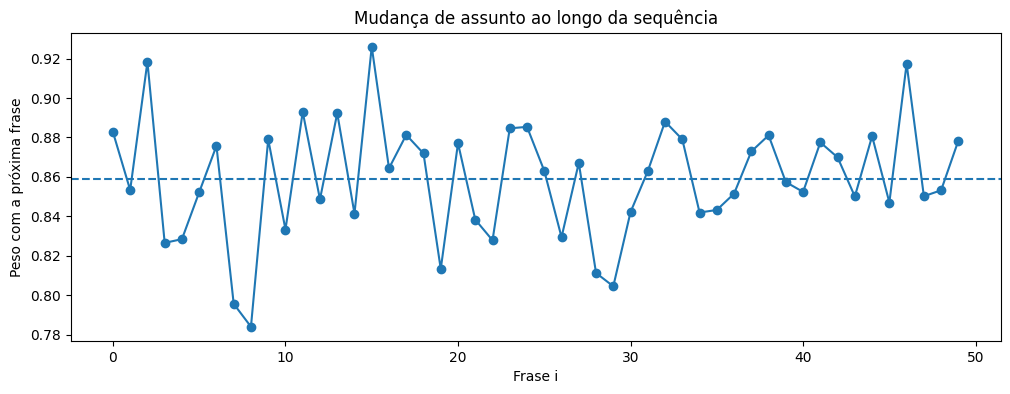

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)

weights = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(len(S_norm) - 1)
])


plt.figure(figsize=(12, 4))
plt.plot(weights, marker='o')
plt.axhline(np.mean(weights), linestyle='--')
plt.xlabel("Frase i")
plt.ylabel("Peso com a próxima frase")
plt.title("Mudança de assunto ao longo da sequência")
plt.show()

In [12]:
def cosine(a, b):
    return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]

k = 3  

pivot_scores = []

for i in range(k, len(S_norm) - k):
    prev_ctx = S_norm[i-k:i].mean(axis=0)
    next_ctx = S_norm[i+1:i+k+1].mean(axis=0)
    score = 1 - cosine(prev_ctx, next_ctx)
    pivot_scores.append((i, score))

pivot_scores.sort(key=lambda x: x[1], reverse=True)

print("Frases mais relevantes para mudança de rumo:")
for i, score in pivot_scores[:5]:
    print(f"\nÍndice {i} | score = {score:.4f}")
    print(sentences[i])

Frases mais relevantes para mudança de rumo:

Índice 23 | score = 0.0870
Não para

Índice 3 | score = 0.0848
Eu quase morri foi vendo aquilo

Índice 14 | score = 0.0834
Por aqui

Índice 4 | score = 0.0820
Não fala tão alto

Índice 9 | score = 0.0736
A gente precisa voltar antes que percebam
